# Figure 1

Assembles Figure 1 from the benchmark results, using the same plotting functions as the benchmark notebooks (`fig_panels.py`) and the shared style (`pub_style.py`).

| Panel | Content | Data (written by) |
|---|---|---|
| a | Model architecture (full width) | `../figures/figure1/architecture.png` (drawn separately; a placeholder is shown until the file exists) |
| b | 3Di identity, ESM3Di vs ProstT5, with the random-baseline median | `quality/results/3di_benchmark.csv` (`quality/3di_alignment_new.ipynb`) |
| c | SCOPe family-level sensitivity | `quality/results/scope_sensitivity.csv` (`quality/scope_family_new.ipynb`) |
| d | Runtime vs number of sequences | `speed/results/final_nseq.csv` (`speed/plot_results.ipynb`) |

Output: `../figures/figure1/figure1.pdf` (vector) and `.png` (600 dpi), 183 mm wide.

In [1]:
# Re-import fig_panels/pub_style when they change, without restarting the kernel
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import FancyBboxPatch

from pub_style import (
    MM, MUTED_TEXT, WIDTH_DOUBLE, add_aligned_panel_labels, save_pub, use_pub_style,
)
from fig_panels import (
    IDENTITY_ARGS, plot_method_scatter, plot_runtime_vs_nseq, plot_scope_level,
)

use_pub_style()
OUT_DIR = Path("../figures/figure1")
ARCHITECTURE_IMAGE = OUT_DIR / "architecture.png"
FIG_HEIGHT = 115 * MM

identity_df = pd.read_csv("quality/results/3di_benchmark.csv")
scope_df = pd.read_csv("quality/results/scope_sensitivity.csv")
nseq_df = pd.read_csv("speed/results/final_nseq.csv")

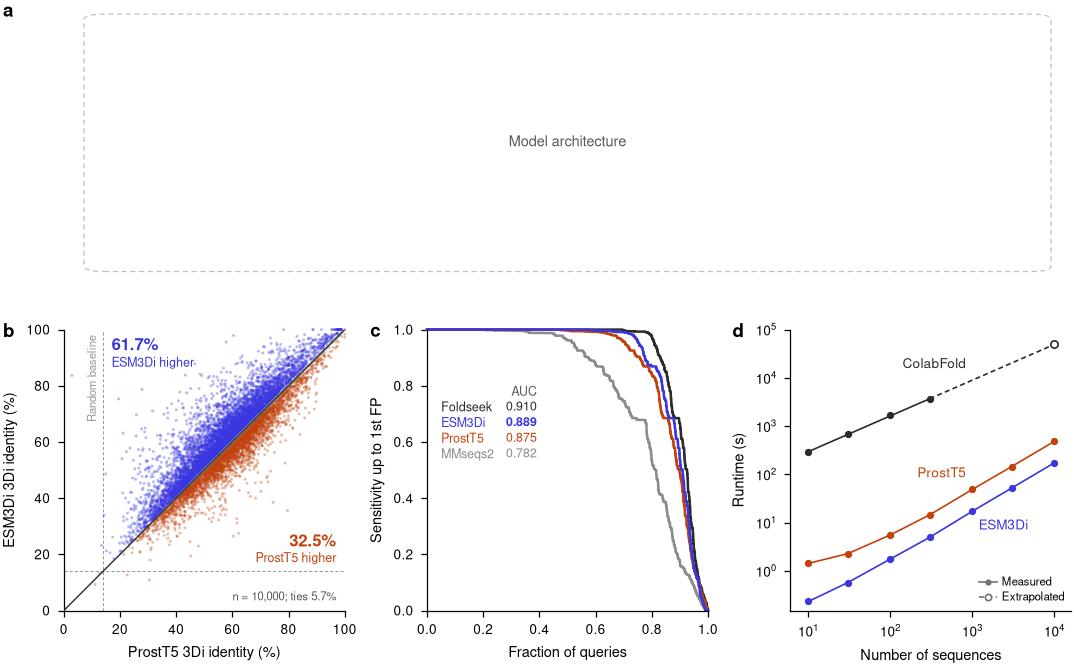

In [2]:
def draw_architecture(ax):
    """Panel a: the architecture image if it exists, otherwise a placeholder of the same area."""
    ax.set_axis_off()
    if ARCHITECTURE_IMAGE.exists():
        ax.imshow(plt.imread(ARCHITECTURE_IMAGE))
        return
    ax.add_patch(FancyBboxPatch((0.02, 0.04), 0.96, 0.92, boxstyle="round,pad=0,rounding_size=0.02",
                                transform=ax.transAxes, fill=False, ec="0.75", lw=0.6, ls=(0, (4, 3))))
    ax.text(0.5, 0.5, "Model architecture", transform=ax.transAxes, ha="center", va="center",
            color=MUTED_TEXT)


fig = plt.figure(figsize=(WIDTH_DOUBLE, FIG_HEIGHT), layout="constrained")
# Top row: architecture over the full width; bottom row: the three result panels
grid = fig.add_gridspec(2, 3, height_ratios=[0.8, 1])
panels = {
    "a": fig.add_subplot(grid[0, :]),
    "b": fig.add_subplot(grid[1, 0]),
    "c": fig.add_subplot(grid[1, 1]),
    "d": fig.add_subplot(grid[1, 2]),
}
draw_architecture(panels["a"])
plot_method_scatter(panels["b"], identity_df, **IDENTITY_ARGS,
                    baseline=identity_df["baseline_identity"].median())
plot_scope_level(panels["c"], scope_df, "Family", show_title=False)
plot_runtime_vs_nseq(panels["d"], nseq_df)
add_aligned_panel_labels(fig, panels)

save_pub(fig, "figure1", OUT_DIR)
plt.show()